# 01 - Análisis Exploratorio de Datos (EDA)

# Clasificación del grado de artrosis de rodilla mediante Machine Learning

**Asignatura:** Machine Learning 1  
**Carrera:** Ingeniería Electrónica - FIUNA  

## Objetivo

Desarrollar un sistema de clasificación multiclase capaz de estimar el grado de artrosis de rodilla a partir de radiografías.

Las clases corresponden a cinco grados:

- 0: Normal
- 1: Dudosa
- 2: Leve
- 3: Moderada
- 4: Severa

Este notebook realiza el análisis exploratorio de datos (EDA), verifica la calidad y distribución del dataset, y genera particiones estratificadas para los modelos posteriores.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Busca automáticamente la raíz del proyecto,
# aunque el notebook se ejecute dentro de /notebooks.
PROJECT_DIR = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data" / "raw").exists()
    ),
    None,
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "No se encontró la carpeta data/raw. "
        "Verificá que el dataset esté dentro de proyecto-rodilla/data/raw/."
    )

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Carpeta del proyecto: {PROJECT_DIR}")
print(f"Carpeta de imágenes: {RAW_DIR}")

pd.set_option("display.max_columns", None)

Carpeta del proyecto: c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla
Carpeta de imágenes: c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\raw


## 1. Carga e identificación del dataset

El dataset contiene radiografías de rodilla organizadas en carpetas según el grado de artrosis. Primero se identifican todas las imágenes disponibles y se registra su ubicación.

In [2]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

images = [
    image_path
    for image_path in RAW_DIR.rglob("*")
    if image_path.suffix.lower() in image_extensions
]

print(f"Cantidad total de imágenes: {len(images)}")

for image_path in images[:10]:
    print(image_path)

Cantidad total de imágenes: 1650
c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\raw\Training\0Normal\NormalG0 (1).png
c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\raw\Training\0Normal\NormalG0 (10).png
c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\raw\Training\0Normal\NormalG0 (100).png
c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\raw\Training\0Normal\NormalG0 (101).png
c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\raw\Training\0Normal\NormalG0 (102).png
c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\raw\Training\0Normal\NormalG0 (103).png
c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\raw\Training\0Normal\NormalG0 (104).png
c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\raw\Training\0Normal\NormalG0 (105).png
c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\ra

## 2. Construcción de la tabla de datos

Cada imagen se representa mediante su ruta, la partición original y su clase clínica. La variable objetivo será el grado de artrosis.

In [3]:
class_order = [
    "0Normal",
    "1Doubtful",
    "2Mild",
    "3Moderate",
    "4Severe",
]

class_labels = {
    "0Normal": "Normal",
    "1Doubtful": "Dudosa",
    "2Mild": "Leve",
    "3Moderate": "Moderada",
    "4Severe": "Severa",
}

class_to_id = {
    "0Normal": 0,
    "1Doubtful": 1,
    "2Mild": 2,
    "3Moderate": 3,
    "4Severe": 4,
}

records = []

for image_path in images:
    records.append({
        "path": str(image_path),
        "split_original": image_path.parent.parent.name,
        "class_name": image_path.parent.name,
    })

df = pd.DataFrame(records)

df["class_name"] = pd.Categorical(
    df["class_name"],
    categories=class_order,
    ordered=True,
)

df["class_label"] = df["class_name"].map(class_labels)
df["target"] = df["class_name"].map(class_to_id).astype(int)

display(df.head())
print(f"Total de imágenes registradas: {len(df)}")

,path,split_original,class_name,class_label,target
0,c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\...,Training,0Normal,Normal,0
1,c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\...,Training,0Normal,Normal,0
2,c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\...,Training,0Normal,Normal,0
3,c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\...,Training,0Normal,Normal,0
4,c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\...,Training,0Normal,Normal,0


Total de imágenes registradas: 1650


## 3. Distribución de clases

Se analiza la cantidad de imágenes por grado de artrosis. Esta verificación permite detectar desbalance entre clases antes de entrenar los modelos.

In [4]:
class_counts = (
    df["class_name"]
    .value_counts()
    .reindex(class_order)
    .rename_axis("Grado")
    .reset_index(name="Cantidad")
)

class_counts["Descripción"] = class_counts["Grado"].map(class_labels)

display(class_counts)

,Grado,Cantidad,Descripción
0,0Normal,514,Normal
1,1Doubtful,477,Dudosa
2,2Mild,232,Leve
3,3Moderate,221,Moderada
4,4Severe,206,Severa


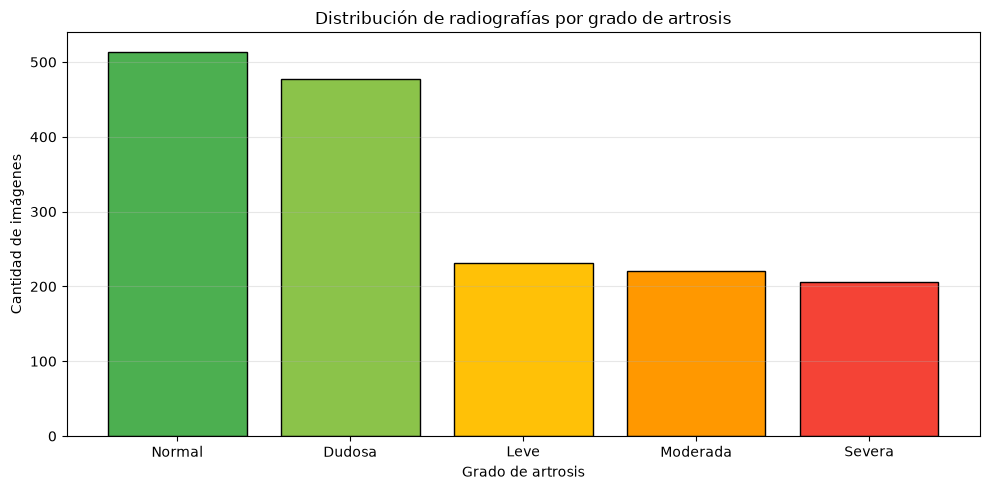

In [5]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_counts["Descripción"],
    class_counts["Cantidad"],
    color=["#4CAF50", "#8BC34A", "#FFC107", "#FF9800", "#F44336"],
    edgecolor="black",
)

plt.title("Distribución de radiografías por grado de artrosis")
plt.xlabel("Grado de artrosis")
plt.ylabel("Cantidad de imágenes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "distribucion_clases.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Inspección visual del dataset

Se muestran ejemplos de radiografías para verificar la correspondencia entre las carpetas, las etiquetas y el contenido visual de cada clase.

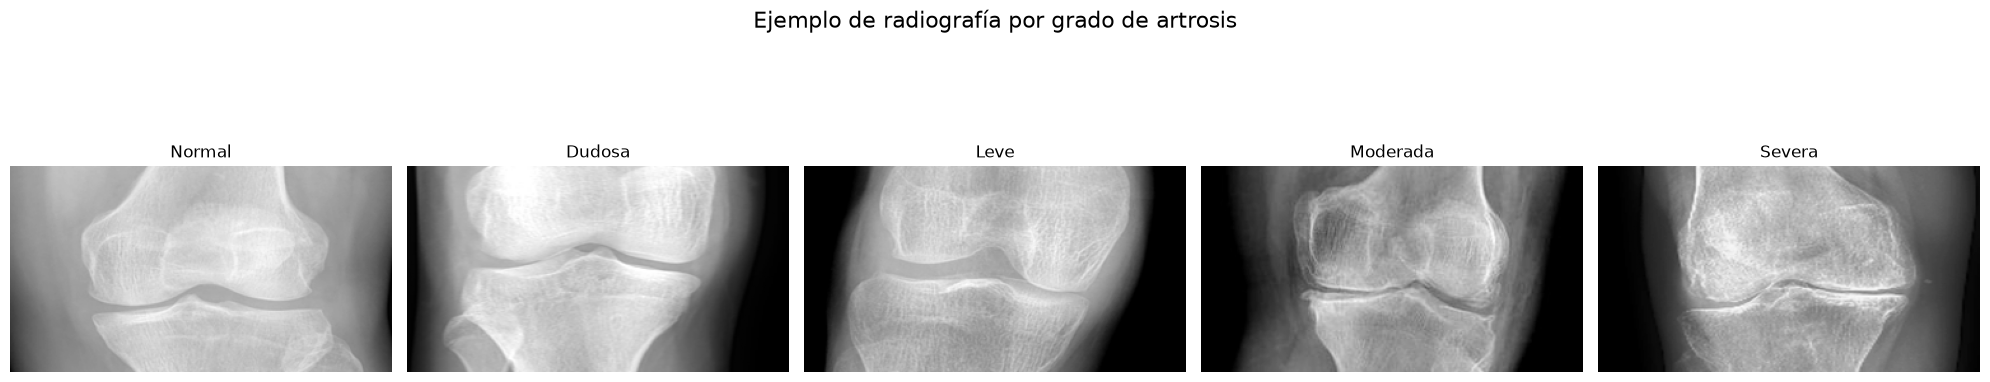

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, class_name in zip(axes, class_order):
    sample_path = df.loc[df["class_name"] == class_name, "path"].iloc[0]

    with Image.open(sample_path) as image:
        image = image.convert("L")
        ax.imshow(image, cmap="gray")

    ax.set_title(class_labels[class_name])
    ax.axis("off")

plt.suptitle("Ejemplo de radiografía por grado de artrosis", fontsize=16)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "muestras_radiografias.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Análisis de dimensiones

Las imágenes pueden tener tamaños diferentes. Se analiza esta variación para definir un preprocesamiento uniforme y prevenir que la resolución se convierta en una fuente de sesgo.

In [7]:
def get_image_size(path):
    with Image.open(path) as image:
        return image.size  # ancho, alto

df[["width", "height"]] = df["path"].apply(
    lambda path: pd.Series(get_image_size(path))
)

display(df[["width", "height"]].describe())

df["resolution"] = (
    df["width"].astype(str) + " x " + df["height"].astype(str)
)

resolution_counts = (
    df.groupby(["width", "height"], observed=True)
    .size()
    .reset_index(name="cantidad")
    .sort_values("cantidad", ascending=False)
)

display(resolution_counts)

,width,height
count,1650.000000,1650.000000
mean,338.327273,161.887273
std,107.560702,0.316355
min,300.000000,161.000000
25%,300.000000,162.000000
50%,300.000000,162.000000
75%,300.000000,162.000000
max,640.000000,162.000000


,width,height,cantidad
0,300,162,1464
1,640,161,186


In [8]:
resolution_by_class = (
    pd.crosstab(
        df["class_name"],
        df["resolution"],
        normalize="index",
    ) * 100
)

print("Porcentaje de cada resolución dentro de cada clase:")
display(resolution_by_class.round(1))

Porcentaje de cada resolución dentro de cada clase:


resolution,300 x 162,640 x 161
class_name,,
0Normal,87.9,12.1
1Doubtful,92.2,7.8
2Mild,82.3,17.7
3Moderate,79.2,20.8
4Severe,100.0,0.0


### Hallazgo sobre las dimensiones

El dataset presenta imágenes de dos resoluciones principales. La proporción de resoluciones varía entre las clases, por lo que existe riesgo de que un modelo aprenda diferencias de formato en lugar de características anatómicas.

Para reducir este efecto, todas las imágenes se normalizarán posteriormente al mismo tamaño mediante redimensionamiento proporcional y padding.

## 6. División estratificada del dataset

El dataset no contiene una partición de prueba independiente. Por ello, se crean tres conjuntos:

- 70% entrenamiento
- 15% validación
- 15% prueba

La división conserva la proporción de cada grado de artrosis y de cada resolución. El conjunto de prueba quedará reservado y no se utilizará durante el ajuste de los modelos.

In [9]:
df["stratum"] = (
    df["class_name"].astype("object").astype(str)
    + "_"
    + df["resolution"]
)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=df["stratum"],
)

validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df["stratum"],
)

train_df = train_df.copy()
validation_df = validation_df.copy()
test_df = test_df.copy()

train_df["split_final"] = "train"
validation_df["split_final"] = "validation"
test_df["split_final"] = "test"

splits_df = pd.concat(
    [train_df, validation_df, test_df],
    ignore_index=True,
)

print("Distribución por clase:")
display(pd.crosstab(
    splits_df["class_name"],
    splits_df["split_final"],
    margins=True,
))

print("\nDistribución por resolución:")
display(pd.crosstab(
    splits_df["resolution"],
    splits_df["split_final"],
    margins=True,
))

Distribución por clase:


split_final,test,train,validation,All
class_name,,,,
0Normal,78,359,77,514
1Doubtful,71,334,72,477
2Mild,35,163,34,232
3Moderate,33,155,33,221
4Severe,31,144,31,206
All,248,1155,247,1650



Distribución por resolución:


split_final,test,train,validation,All
resolution,,,,
300 x 162,220,1025,219,1464
640 x 161,28,130,28,186
All,248,1155,247,1650


In [10]:
output_columns = [
    "path",
    "class_name",
    "class_label",
    "target",
    "width",
    "height",
    "resolution",
    "split_final",
]

splits_df[output_columns].to_csv(
    PROCESSED_DIR / "dataset_splits.csv",
    index=False,
)

print("Archivo creado correctamente:")
print(PROCESSED_DIR / "dataset_splits.csv")

Archivo creado correctamente:
c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\proyecto-rodilla\data\processed\dataset_splits.csv


## Conclusiones del análisis exploratorio

- El dataset contiene 1.650 radiografías de rodilla distribuidas en cinco grados de artrosis.
- Las clases presentan desbalance, con mayor representación de Normal y Dudosa.
- Se identificaron dos resoluciones principales de imagen, cuya distribución no es idéntica entre clases.
- Se generaron particiones estratificadas de entrenamiento, validación y prueba.
- En los notebooks siguientes se aplicará un preprocesamiento uniforme y se evaluarán los modelos mediante F1 macro, accuracy balanceado y matrices de confusión.